# Experiment 3 Analysis: KASBench Evaluation

What do I want to demonstrate
- KASBench metrics accurately describe autoscaler performance
- KASBench metrics are autoscaler agnostic
- KASBench metrics are repeatable 
- KASBench results are reproducible
- Theta and Tau measure two distinct qualities of autoscaler performance
- Synchronous and asysnchronous metrics measure two distinct qualities of autoscaler performance
- KASBench results were not confounded by cluster resource insufficiency
- 7 repetitions per autoscaler of 1 hour each is adequate
- KASBench is robust to inherent cloud variability
- KASBench produces realistic and accurate signals under load


Evidence
- All autoscalers are significantly better than no autoscaler (ANOVA
- Post-hoc tests show all autoscalers are significantly different from each other (Tukey HSD test)
- KASBench metrics are highly correlated with each other (Pearson correlation)
- KASBench metrics are highly correlated with ground truth metrics (Pearson correlation)
- KASBench metrics are consistent across multiple runs (standard deviation)



## Imports

In [222]:
import json

import pandas as pd
import numpy as np
import pyperclip
import matplotlib.pyplot as plt
from scipy.stats import t
from scipy import stats



## Constants

In [223]:
run_id = "experiment-3-run-60m-7rep-a"

trial_summary_parquet = f"../data/{run_id}/{run_id}-trial-summary.parquet"
asynchronous_trials_parquet = f"../data/{run_id}/{run_id}-asynchronous-trial.parquet"
synchronous_theta_trials_parquet = f"../data/{run_id}/{run_id}-synchronous-theta-trials.parquet"
synchronous_tau_trials_parquet = f"../data/{run_id}/{run_id}-synchronous-tau-trials.parquet"
autoscaler_summary_parquet = f"../data/{run_id}/{run_id}-autoscaler-summary.parquet"
cost_metrics_parquet = f"../data/{run_id}/{run_id}-cost-metric-trials.parquet"
summary_parquet = f"../data/{run_id}/{run_id}-summary.parquet"
lag_parquet = f"../data/{run_id}/{run_id}-lag.parquet"

autoscaler_order=["none","hpa","keda","vpa"]


metric_description = [
    {"name": "mean_response_time", "description": "Mean Response Time"}, 
    {"name": "failure_rate", "description": "Failure Rate"}, 
    {"name": "roundtrip_completion_percentage", "description": "Roundtrip Completion Percentage"},
    {"name": "theta_a", "description": "Asynchronous Deviation"}, 
    {"name": "tau_a", "description": "Asynchronous Time Slices"}, 
    {"name": "theta_rt", "description": "Synchronous Response Time Deviation"}, 
    {"name": "theta_fr", "description": "Synchronous Failure Rate Deviation"}, 
    {"name": "tau_rt", "description": "Synchronous Response Time Time Slices"}, 
    {"name": "tau_fr", "description": "Synchronous Failure Rate Time Slices"},
    {"name": "c_bar_cpu", "description": "Requested CPU Cost"}, 
    {"name": "c_bar_mem", "description": "Requested Memory Cost"},
    ]

# metrics = ["mean_response_time", "failure_rate", "roundtrip_completion_percentage",
#     "theta_a", "tau_a", "theta_rt", "theta_fr", "tau_rt", "tau_fr",
#     "c_bar_cpu", "c_bar_mem"]

metrics = [m["name"] for m in metric_description]
metric_lookup = {m["name"]: m["description"] for m in metric_description}




## Trial Summary

Main results aggregated to the trial level

In [224]:
trial_summary_df = pd.read_parquet(trial_summary_parquet)

trial_summary_df

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,failure_rate,sd_failure_rate,quantity_ordered,quantity_placed,quantity_filled,roundtrip_completion_percentage
0,hpa,trial0002,544329,76.362384,76.108842,329.341188,76.361455,76.108774,544340,11,0.000020,0.004495,126682308,126682308,1516449,1.197049
1,hpa,trial0005,546210,75.829941,74.364845,336.587441,75.848690,75.682404,546222,12,0.000022,0.004687,127126099,127126099,1528628,1.202450
2,hpa,trial0009,542924,87.210382,299.397673,327.746207,87.209668,299.394010,542938,14,0.000026,0.005078,123424627,123424627,1648717,1.335809
3,hpa,trial0013,541791,78.065713,231.513069,307.453807,81.308312,642.449103,541826,35,0.000065,0.008037,122188873,122188873,1616088,1.322615
4,hpa,trial0019,547983,83.378331,341.162238,282.101725,90.645515,965.626007,548058,75,0.000137,0.011697,125483949,125483949,1701313,1.355801
5,hpa,trial0024,552592,73.166351,114.223026,278.778534,73.164759,114.221458,552611,19,0.000034,0.005864,131890164,131890164,1471273,1.115529
6,hpa,trial0026,544345,74.806688,78.807086,334.016953,77.178714,464.739653,544396,51,0.000094,0.009678,124280449,124280449,1291268,1.038995
7,keda,trial0006,538895,79.512232,69.400738,318.343177,101.366267,1630.274007,539007,112,0.000208,0.014413,124655496,124655496,8237874,6.608512
8,keda,trial0011,538658,83.908554,250.281371,312.052657,99.393769,1235.028195,538791,133,0.000247,0.015710,123612980,123612980,7635049,6.176575
9,keda,trial0012,539142,91.603109,281.119939,346.905453,104.865493,1215.608590,539247,105,0.000195,0.013953,125486357,125486357,8784754,7.000565


In [225]:
asynchronous_trial_summary_df = pd.read_parquet(asynchronous_trials_parquet)
asynchronous_trial_summary_df

,autoscaler,trial_id,lag_mean,arrival_rate_mean,w_mean,theta_a,tau_a
0,hpa,trial0002,13986.864537,30.872900,575.300074,50.000000,50.000000
1,hpa,trial0005,13552.256637,30.656096,567.237676,50.174335,52.876106
2,hpa,trial0009,12856.025612,30.344543,539.133062,50.120183,51.559020
3,hpa,trial0013,12832.889868,30.247387,541.342175,50.057424,50.220264
4,hpa,trial0019,12525.584783,30.366259,504.657585,50.484602,55.652174
5,hpa,trial0024,14832.208609,31.708908,575.412570,50.000000,50.000000
6,hpa,trial0026,12835.486784,30.619142,526.930567,50.254334,53.083700
7,keda,trial0006,51.136929,28.496892,1.840747,32.473120,51.244813
8,keda,trial0011,49.872407,28.735499,1.855145,28.945061,48.132780
9,keda,trial0012,48.433610,28.520092,1.683112,26.918867,42.012448


In [226]:
synchronous_theta_trial_summmary_df = pd.read_parquet(synchronous_theta_trials_parquet)
synchronous_theta_trial_summmary_df

,autoscaler,trial_id,theta_rt,theta_fr,time_slices,requests,successful_requests,failures
0,hpa,trial0002,8.622199,4.166667,240,544340,544329,11
1,hpa,trial0005,9.196229,4.979253,241,546222,546210,12
2,hpa,trial0009,8.872382,3.333333,240,542938,542924,14
3,hpa,trial0013,6.701742,4.149378,241,541826,541791,35
4,hpa,trial0019,7.417609,7.053942,241,548058,547983,75
5,hpa,trial0024,6.240676,4.564315,241,552611,552592,19
6,hpa,trial0026,8.349306,4.149378,241,544396,544345,51
7,keda,trial0006,10.912601,3.750000,240,539007,538895,112
8,keda,trial0011,8.549334,8.298755,241,538791,538658,133
9,keda,trial0012,10.674025,2.083333,240,539247,539142,105


In [227]:
synchronous_tau_trial_summmary_df = pd.read_parquet(synchronous_tau_trials_parquet)
synchronous_tau_trial_summmary_df

,autoscaler,trial_id,tau_rt,tau_fr,time_slices,requests,successful_requests,failures
0,hpa,trial0002,62.083333,4.166667,240,544340,544329,11
1,hpa,trial0005,57.676349,4.979253,241,546222,546210,12
2,hpa,trial0009,53.112033,3.319502,241,542938,542924,14
3,hpa,trial0013,54.356846,4.149378,241,541826,541791,35
4,hpa,trial0019,55.601660,6.639004,241,548058,547983,75
5,hpa,trial0024,60.165975,4.564315,241,552611,552592,19
6,hpa,trial0026,60.995851,4.149378,241,544396,544345,51
7,keda,trial0006,56.666667,3.750000,240,539007,538895,112
8,keda,trial0011,57.261411,8.298755,241,538791,538658,133
9,keda,trial0012,57.676349,2.489627,241,539247,539142,105


In [228]:
cost_detail_summary_df = pd.read_parquet(cost_metrics_parquet)
cost_detail_summary_df

,autoscaler,trial_id,c_bar_cpu,c_bar_mem
0,hpa,trial0002,0.146884,0.186662
1,hpa,trial0005,0.131057,0.143695
2,hpa,trial0009,0.132205,0.145164
3,hpa,trial0013,0.142430,0.174023
4,hpa,trial0019,0.144718,0.150442
5,hpa,trial0024,0.151881,0.183181
6,hpa,trial0026,0.135895,0.156819
7,keda,trial0006,0.249344,0.226291
8,keda,trial0011,0.184261,0.180207
9,keda,trial0012,0.213468,0.203759


In [229]:
# merge all the trial summaries
trial_summary_df = trial_summary_df.merge(asynchronous_trial_summary_df[["autoscaler", "trial_id", "theta_a", "tau_a"]]
     , on=["autoscaler", "trial_id"])

trial_summary_df = trial_summary_df.merge(synchronous_theta_trial_summmary_df[["autoscaler", "trial_id", "theta_rt", "theta_fr"]]
     , on=["autoscaler", "trial_id"])


trial_summary_df = trial_summary_df.merge(synchronous_tau_trial_summmary_df[["autoscaler", "trial_id", "tau_rt", "tau_fr"]]
     , on=["autoscaler", "trial_id"])

trial_summary_df = trial_summary_df.merge(cost_detail_summary_df
     , on=["autoscaler", "trial_id"])



trial_summary_df

,autoscaler,trial_id,successful_requests,mean_response_time,sd_response_time,p99_response_time,unmodified_mean_response_time,sd_unmodified_response_time,requests,failures,...,quantity_filled,roundtrip_completion_percentage,theta_a,tau_a,theta_rt,theta_fr,tau_rt,tau_fr,c_bar_cpu,c_bar_mem
0,hpa,trial0002,544329,76.362384,76.108842,329.341188,76.361455,76.108774,544340,11,...,1516449,1.197049,50.000000,50.000000,8.622199,4.166667,62.083333,4.166667,0.146884,0.186662
1,hpa,trial0005,546210,75.829941,74.364845,336.587441,75.848690,75.682404,546222,12,...,1528628,1.202450,50.174335,52.876106,9.196229,4.979253,57.676349,4.979253,0.131057,0.143695
2,hpa,trial0009,542924,87.210382,299.397673,327.746207,87.209668,299.394010,542938,14,...,1648717,1.335809,50.120183,51.559020,8.872382,3.333333,53.112033,3.319502,0.132205,0.145164
3,hpa,trial0013,541791,78.065713,231.513069,307.453807,81.308312,642.449103,541826,35,...,1616088,1.322615,50.057424,50.220264,6.701742,4.149378,54.356846,4.149378,0.142430,0.174023
4,hpa,trial0019,547983,83.378331,341.162238,282.101725,90.645515,965.626007,548058,75,...,1701313,1.355801,50.484602,55.652174,7.417609,7.053942,55.601660,6.639004,0.144718,0.150442
5,hpa,trial0024,552592,73.166351,114.223026,278.778534,73.164759,114.221458,552611,19,...,1471273,1.115529,50.000000,50.000000,6.240676,4.564315,60.165975,4.564315,0.151881,0.183181
6,hpa,trial0026,544345,74.806688,78.807086,334.016953,77.178714,464.739653,544396,51,...,1291268,1.038995,50.254334,53.083700,8.349306,4.149378,60.995851,4.149378,0.135895,0.156819
7,keda,trial0006,538895,79.512232,69.400738,318.343177,101.366267,1630.274007,539007,112,...,8237874,6.608512,32.473120,51.244813,10.912601,3.750000,56.666667,3.750000,0.249344,0.226291
8,keda,trial0011,538658,83.908554,250.281371,312.052657,99.393769,1235.028195,538791,133,...,7635049,6.176575,28.945061,48.132780,8.549334,8.298755,57.261411,8.298755,0.184261,0.180207
9,keda,trial0012,539142,91.603109,281.119939,346.905453,104.865493,1215.608590,539247,105,...,8784754,7.000565,26.918867,42.012448,10.674025,2.083333,57.676349,2.489627,0.213468,0.203759


### Table

In [230]:
def generate_latex_trial_summary_table(df: pd.DataFrame, caption: str = "Trial Summary Metrics", label: str = "tab:trial_summary") -> str:
    """
    Generates a modern, booktabs-styled LaTeX table from a summary DataFrame.
    """
    # Create a working copy to avoid mutating the original dataframe
    formatted_df = df.copy()

    # formatted_df = formatted_df.drop(columns=["quantity_ordered", "quantity_placed", "quantity_filled"])
    formatted_df = formatted_df[["autoscaler", "mean_response_time", "p99_response_time", "failure_rate", "roundtrip_completion_percentage"]]
    formatted_df.columns = ["Autoscaler", "Mean Response Time (ms)", "99% Tail Latency (ms)", "Failure Rate", "Roundtrip Rate"]
    formatted_df.Autoscaler = formatted_df.Autoscaler.str.upper()
    formatted_df["Failure Rate"] *= 100.0

    # Define custom formatting rules
    formatters = {
        'Mean Response Time (ms)': '{:.2f}'.format,
        '99% Tail Latency (ms)': '{:.2f}'.format,
        'Roundtrip Rate': '{:.2f}'.format,
        'Failure Rate': '{:.4f}'.format,
    }

    # Left-align the category/name column and right-align numeric columns
    column_alignment = "lrrrr"

    # Export using modern booktabs rules without row index
    latex_code = formatted_df.to_latex(
        index=False,
        formatters=formatters,
        column_format=column_alignment,
        caption=caption,
        label=label,
        position="htbp",
        escape=True  # Automatically escapes '%' and other special characters
    )

    return latex_code

trial_summary_table = generate_latex_trial_summary_table(trial_summary_df, caption="Experiment 3 trial summary observed metrics", label="tab:experiment_3_trial_summary_observed_metrics")
pyperclip.copy(trial_summary_table)

### Scatter Plot

In [231]:

def plot_combined_autoscaler_metrics(
    trial_summary: pd.DataFrame,
    *,
    autoscaler_order: list[str] | None = None,
    confidence_level: float = 0.95,
    random_seed: int = 42,
    layout: str = "vertical",  
    metric_type: str = None,
) -> tuple[plt.Figure, np.ndarray]:
    """Plot response time, failure rate, and round-trip completion rate across autoscalers.

    Parameters
    ----------
    trial_summary : pd.DataFrame
        DataFrame containing columns:
          - 'autoscaler'
          - 'trial_id'
          - 'mean_response_time' (in ms)
          - 'failure_rate' (as proportion 0.0 - 1.0)
          - 'roundtrip_completion_percentage' (as percentage 0.0 - 100.0)
    autoscaler_order : list[str] | None
        Explicit ordering of autoscalers. Any present autoscalers not listed
        are appended alphabetically.
    confidence_level : float
        Confidence level for Student-t error bars (default 0.95).
    random_seed : int
        Seed for reproducible jitter.
    layout : str
        Subplot arrangement: 'vertical' (3 rows, 1 col) or 'horizontal' (1 row, 3 cols).

    Returns
    -------
    tuple[plt.Figure, np.ndarray]
        The figure and array of Axes objects. DataFrames containing summary
        statistics are attached to `axes[0].summary_df`, `axes[1].summary_df`,
        and `axes[2].summary_df`.
    """
    required_cols = {
        "autoscaler",
        "trial_id",
        "mean_response_time",
        "failure_rate",
        "roundtrip_completion_percentage",
        "theta_a",
        "tau_a",
        "theta_rt", 
        "theta_fr", 
        "tau_rt", 
        "tau_fr",
        "c_bar_cpu",
        "c_bar_mem",
        
    }
    missing_cols = required_cols - set(trial_summary.columns)
    if missing_cols:
        raise ValueError(
            f"trial_summary is missing required columns: {sorted(missing_cols)}"
        )

    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be between 0 and 1.")

    plot_df = trial_summary[list(required_cols)].copy()

    # Validate duplicate trial records per autoscaler
    duplicate_mask = plot_df.duplicated(
        subset=["autoscaler", "trial_id"], keep=False
    )
    if duplicate_mask.any():
        bad_dupes = plot_df.loc[
            duplicate_mask, ["autoscaler", "trial_id"]
        ].sort_values(["autoscaler", "trial_id"])
        raise ValueError(f"Duplicate autoscaler/trial_id rows found:\n{bad_dupes}")

    # Coerce numeric columns and validate bounds
    for col in [
        "mean_response_time",
        "failure_rate",
        "roundtrip_completion_percentage",
    ]:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")
        if plot_df[col].isna().any():
            raise ValueError(f"Column '{col}' contains missing or non-numeric values.")

    if not plot_df["failure_rate"].between(0, 1).all():
        raise ValueError("failure_rate must be expressed as a proportion in [0, 1].")

    if not plot_df["roundtrip_completion_percentage"].between(0, 100).all():
        raise ValueError(
            "roundtrip_completion_percentage must be between 0 and 100."
        )

    # Establish common autoscaler ordering
    present_autoscalers = sorted(plot_df["autoscaler"].astype(str).unique())
    if autoscaler_order is None:
        autoscalers = present_autoscalers
    else:
        autoscalers = [a for a in autoscaler_order if a in present_autoscalers]
        autoscalers.extend([a for a in present_autoscalers if a not in autoscalers])

    if not autoscalers:
        raise ValueError("No autoscaler data available to plot.")

    # Define metric specifications: (column_name, scale_factor, y_label, title, min_val, max_val)
    metric_configs = [
        {
            "col": "mean_response_time",
            "scale": 1.0,
            "ylabel": "Mean Response Time (ms)",
            "title": f"Mean Response Time by Autoscaler\n(Trial means with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": None,
            "metric_type": "raw",
        },
        {
            "col": "failure_rate",
            "scale": 100.0,  # Convert proportion to percentage for display
            "ylabel": "Failure Rate (%)",
            "title": f"Failure Rate by Autoscaler\n(Trial rates with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "raw",
        },
        {
            "col": "roundtrip_completion_percentage",
            "scale": 1.0,
            "ylabel": "Round-Trip Completion (%)",
            "title": f"Round-Trip Completion by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "raw",
        },
        {
            "col": "theta_a",
            "scale": 1.0,
            "ylabel": "Deviation (%)",
            "title": r"Asynchronous Deviation ($\theta^A$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_asynch",
        },
        {
            "col": "tau_a",
            "scale": 1.0,
            "ylabel": "Underprovisioned time slices (%)",
            "title": r"Asynchronous Underprovisioned Time Slices ($\tau^A$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_asynch",
        },
        {
            "col": "theta_rt",
            "scale": 1.0,
            "ylabel": "Deviation (%)",
            "title": r"Synchronous Response Time Deviation from Baseline ($\theta^{RT}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_synch",
        },
        {
            "col": "tau_rt",
            "scale": 1.0,
            "ylabel": "Underprovisioned time slices (%)",
            "title": r"Synchronous Response Time Underprovisioned Time Slices ($\tau^{RT}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_synch",
        },
        {
            "col": "theta_fr",
            "scale": 1.0,
            "ylabel": "Deviation (%)",
            "title": r"Synchronous Failure Rate Deviation from Baseline ($\theta^{FR}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_synch",
        },
        {
            "col": "tau_fr",
            "scale": 1.0,
            "ylabel": "Underprovisioned time slices (%)",
            "title": r"Synchronous Failure Rate Underprovisioned Time Slices ($\tau^{FR}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "derived_synch",
        },
        {
            "col": "c_bar_cpu",
            "scale": 1.0,
            "ylabel": "Deviation (%)",
            "title": r"CPU Cost Deviation from Baseline ($\overline{C}_{CPU}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "cost",
        },
        {
            "col": "c_bar_mem",
            "scale": 1.0,
            "ylabel": "Deviation (%)",
            "title": r"Memory Cost Deviation from Baseline ($\overline{C}_{MEM}$) " + f"by Autoscaler\n(Trial percentages with {confidence_level:.0%} CI)",
            "clip_lower": 0.0,
            "clip_upper": 100.0,
            "metric_type": "cost",
        },
    ]
    if metric_type:
        metric_configs = [cfg for cfg in metric_configs if cfg["metric_type"] == metric_type]

    # Initialize subplots
    len_metric_configs = len(metric_configs)
    if layout == "horizontal":
        fig, axes = plt.subplots(1, len_metric_configs, figsize=(18, 5.5), sharex=True)
    else:
        fig, axes = plt.subplots(len_metric_configs, 1, figsize=(8, 14), sharex=True)

    alpha = 1 - confidence_level

    # Render each metric
    for ax_idx, (ax, cfg) in enumerate(zip(axes, metric_configs)):
        rng = np.random.default_rng(random_seed)
        col = cfg["col"]
        scale = cfg["scale"]
        clip_lower = cfg["clip_lower"]
        clip_upper = cfg["clip_upper"]

        summary_rows = []

        for pos, autoscaler in enumerate(autoscalers):
            sub_df = plot_df[plot_df["autoscaler"] == autoscaler].sort_values(
                "trial_id"
            )
            vals = sub_df[col].to_numpy(dtype=float) * scale
            n_trials = len(vals)

            # Jittered trial scatter
            jittered_x = rng.normal(loc=pos, scale=0.045, size=n_trials)
            ax.scatter(
                jittered_x,
                vals,
                s=40,
                alpha=0.6,
                label="Individual trial" if pos == 0 else None,
                zorder=2,
            )

            mean_val = vals.mean() if n_trials > 0 else np.nan

            if n_trials >= 2:
                std_val = vals.std(ddof=1)
                se_val = std_val / np.sqrt(n_trials)
                t_crit = t.ppf(1 - alpha / 2, df=n_trials - 1)
                half_width = t_crit * se_val

                ci_lower = mean_val - half_width
                ci_upper = mean_val + half_width

                if clip_lower is not None:
                    ci_lower = max(clip_lower, ci_lower)
                if clip_upper is not None:
                    ci_upper = min(clip_upper, ci_upper)

                yerr = np.array([[mean_val - ci_lower], [ci_upper - mean_val]])
            else:
                std_val = se_val = half_width = np.nan
                ci_lower = ci_upper = np.nan
                yerr = None

            ax.errorbar(
                pos,
                mean_val,
                yerr=yerr,
                fmt="o",
                markersize=8,
                capsize=6,
                capthick=1.5,
                linewidth=2,
                label=f"Mean and {confidence_level:.0%} CI" if pos == 0 else None,
                zorder=3,
            )

            summary_rows.append(
                {
                    "autoscaler": autoscaler,
                    "trials": n_trials,
                    "mean": mean_val,
                    "std": std_val,
                    "se": se_val,
                    "ci_lower": ci_lower,
                    "ci_upper": ci_upper,
                }
            )

        ax.set_title(cfg["title"])
        ax.set_ylabel(cfg["ylabel"])
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(loc="best")
        ax.summary_df = pd.DataFrame(summary_rows)

    # Configure shared x-axis ticks on the subplots
    autoscaler_labels = [a.upper() for a in autoscalers]
    for ax in axes:
        ax.set_xticks(range(len(autoscalers)))
        ax.set_xticklabels(autoscaler_labels)

    if layout == "horizontal":
        for ax in axes:
            ax.set_xlabel("Autoscaler")
    else:
        # For vertical stacking, only label the bottom axis to avoid clutter
        axes[-1].set_xlabel("Autoscaler")

    fig.tight_layout()
    return fig, axes


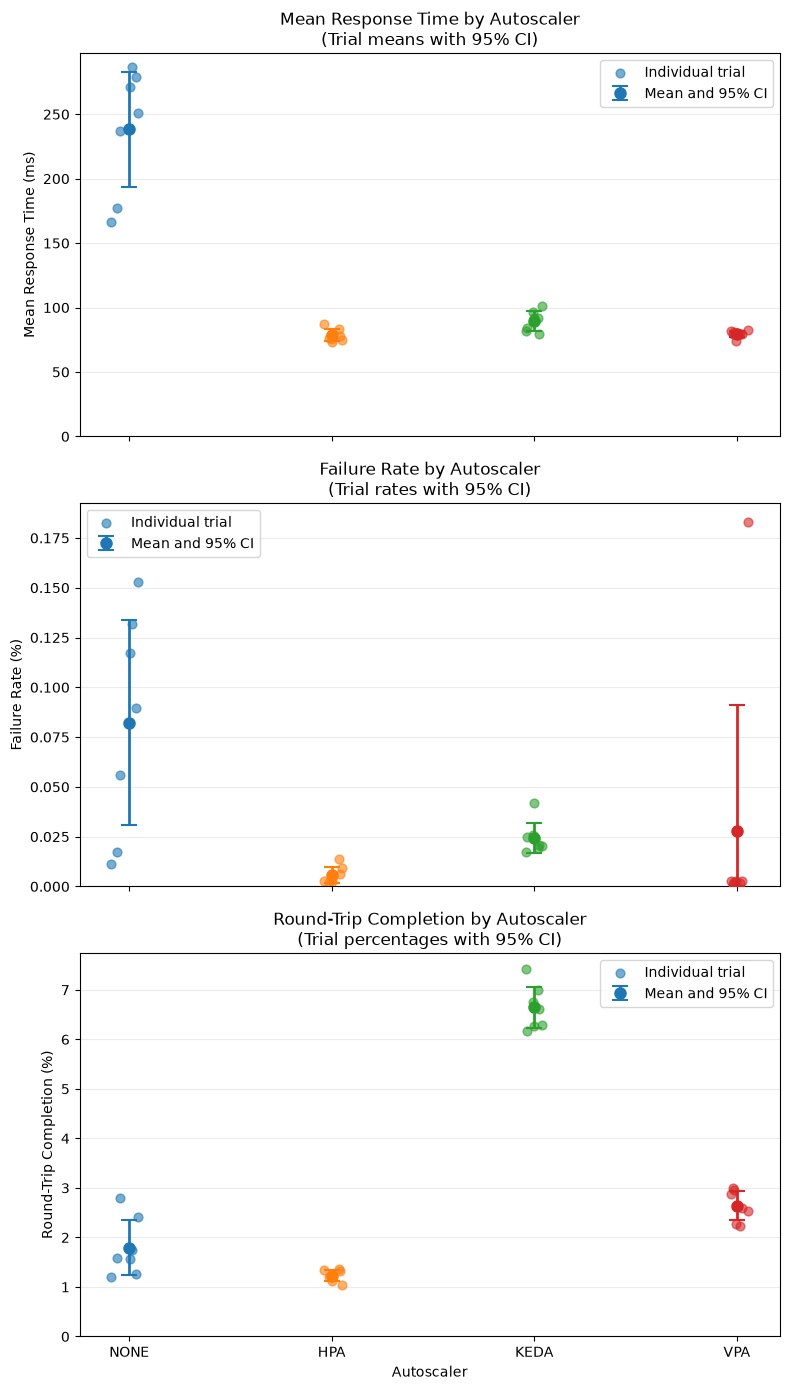

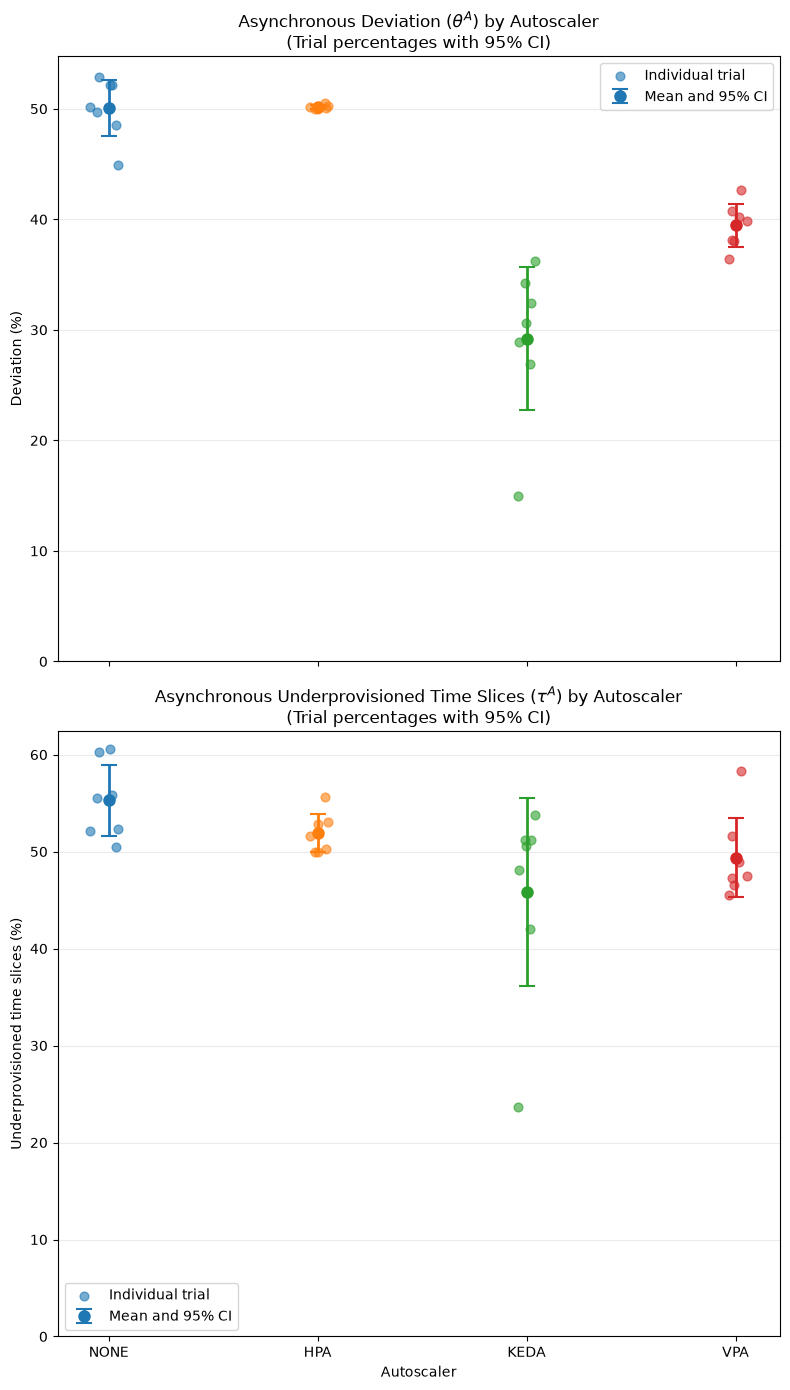

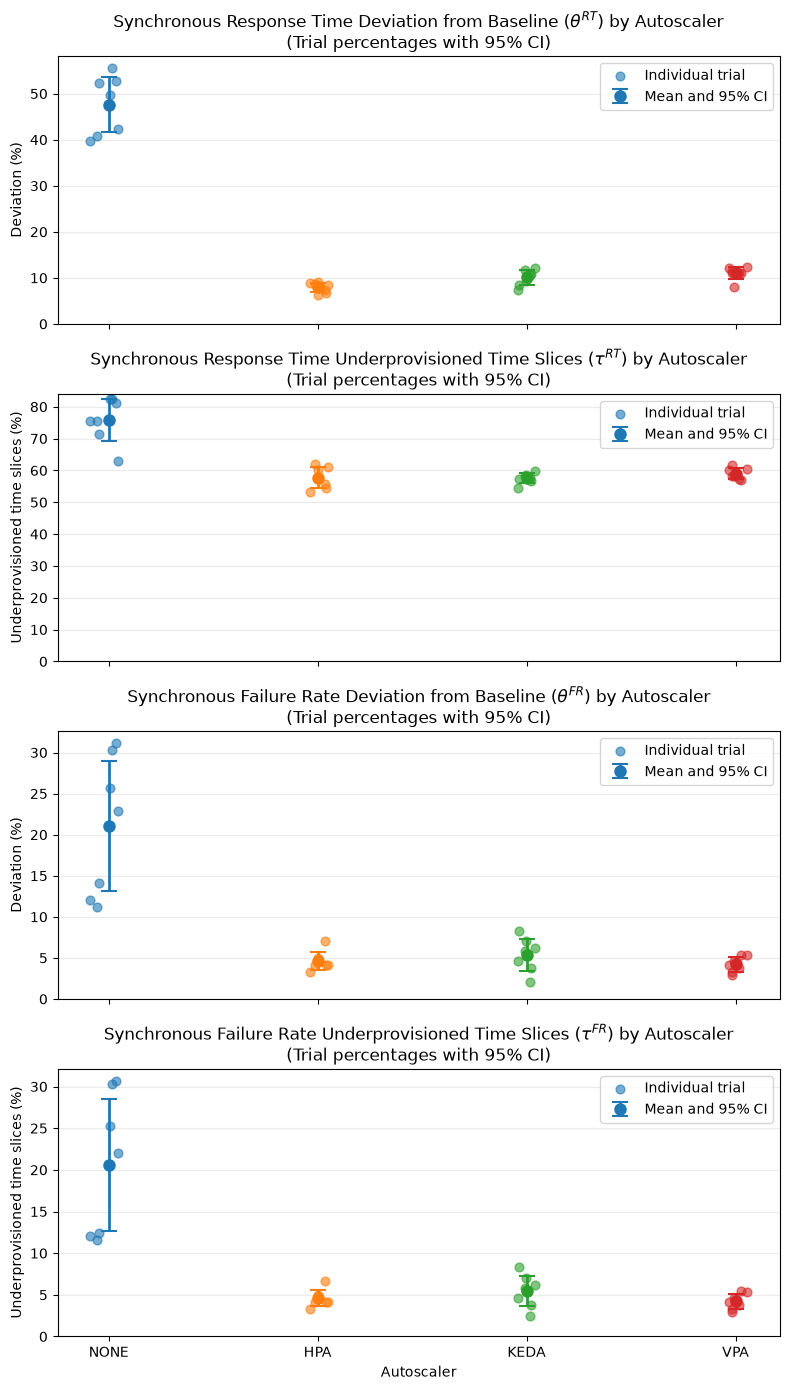

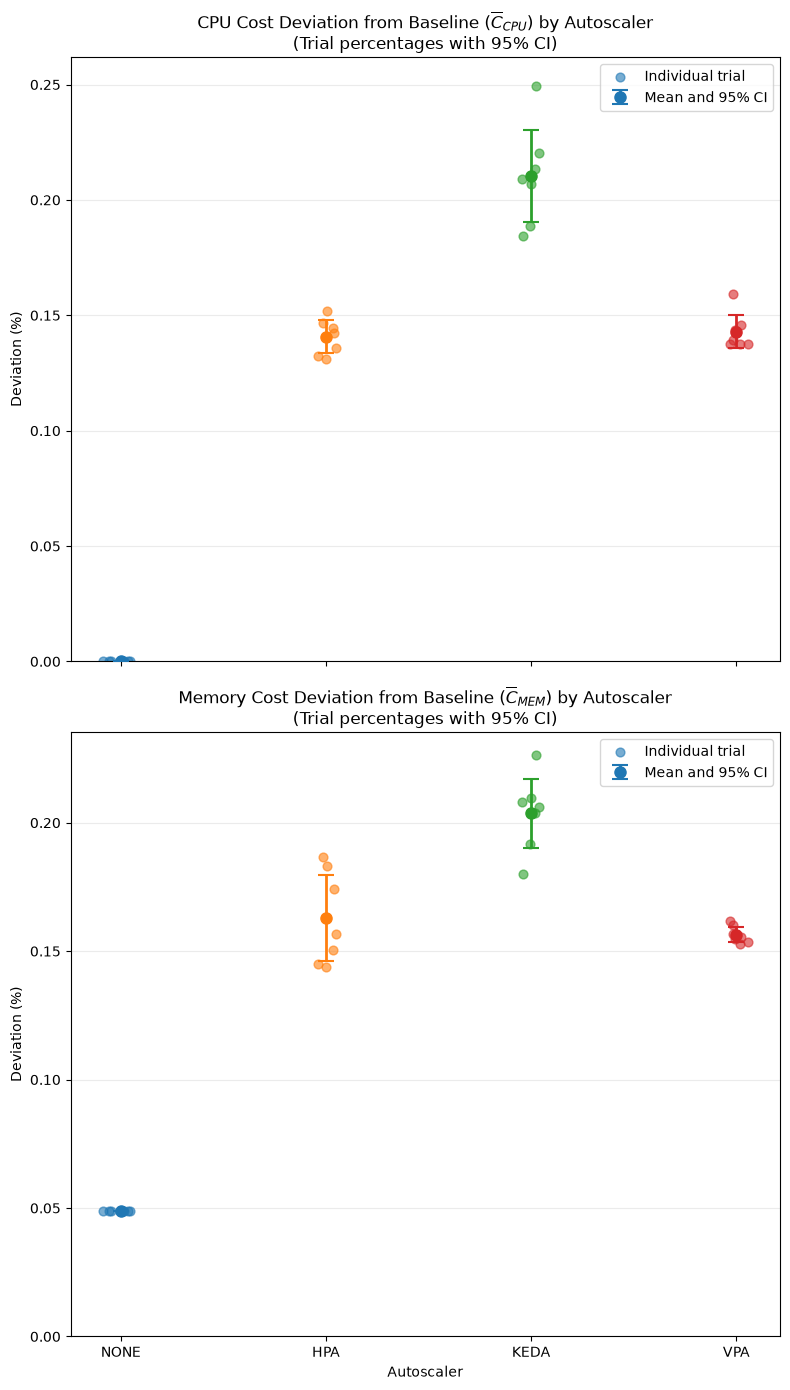

In [232]:
metric_types = ["raw", "derived_asynch", "derived_synch", "cost"]
for metric_type in metric_types:
    fig, axes = plot_combined_autoscaler_metrics(
        trial_summary_df, 
        autoscaler_order=autoscaler_order,
        metric_type=metric_type)
    # save figure to a file
    fig.savefig(r"../figures/experiment_3_main_results_{metric_type}.png", dpi=300, bbox_inches='tight')



## Analyze repeatability and reproducibility

Analysis of reeatability and robustness


### Variance/homoscedasticity (TABLE)

The following code performs two Brown-Forsythe Leven's tests of homogeneity of variance for the response time, failure rate, and roundtrip completion percentage metrics.  We test two hypotheses.  The first evaluates the null hypothesis $\sigma^2_{none} = \sigma^2_{hpa} = \sigma^2_{keda} = \sigma^2_{vpa}$.  The second version excludes the baseline (no autoscaler), under the assumption without autoscaling, the baseline class will be characterized by resource overutilization ($\rho \to 1$) resulting in instability-driven variance.  This is by design, as pods in the experiment are intentionally sized based on 15th percentile load intensity.  The null hypothesis for the second test can therefore be expressed as $\sigma^2_{hpa} = \sigma^2_{keda} = \sigma^2_{vpa}$.  $\alpha$ is $0.05$.  The Bonferroni correction was applied.

In the first case, the null hypothesis is rejected for response time, suggesting unequal variance.  The null hypothesis cannot be rejected for failure rate and round-trip completion percentage.  In the second case, the null hypothesis is not rejected for any metric, suggesting equal variance between the autoscalers.  The post-hoc variance test below adds support for preferring the second null hypothesis as the more relevant comparison of variances for the purpose of ascertaining repeatability.

In [233]:

def brown_forsythe_levene_test(trial_summary_df: pd.DataFrame, alpha: float = 0.05, 
    exclude_none=True, verbose=False) -> pd.DataFrame:
    """
    Conducts a Brown-Forsythe Levene's test for homogeneity of variance
    across autoscalers for key performance metrics.

    Parameters
    ----------
    trial_summary_df : pd.DataFrame
        DataFrame containing trial-level metrics with columns:
        - 'autoscaler'
        - 'mean_response_time'
        - 'failure_rate'
        - 'roundtrip_completion_percentage'
    alpha : float
        Significance level for the test (default 0.05).
    exclude_none: exclude "none" (no autoscaler/baseline) from the comparisons

    Returns
    -------
    pd.DataFrame
        One row per metric with columns:
        - 'metric'
        - 'exclude_none'
        - 'statistic' (Brown-Forsythe W)
        - 'p_value'
        - 'alpha'
        - 'alpha_corrected' (Bonferroni-adjusted)
        - 'reject_h0'
        - 'conclusion'
    """

    results = []

    if verbose:
        print("-" * 60)
        print()
        if exclude_none:
            print("Brown-Forsythe Leven's test for homogeneity of variance across autoscalers excluding baseline")
        else:
            print("Brown-Forsythe Leven's test for homogeneity of variance across autoscalers including baseline")
        
        print()

    df = trial_summary_df.copy()
    if exclude_none:
        df = df[df['autoscaler'] != 'none']

    # metrics to evaluate
    metrics = [
        'mean_response_time',
        'unmodified_mean_response_time',
        'failure_rate',
        'roundtrip_completion_percentage',
        'theta_a',
        'tau_a',
        'theta_rt',
        'theta_fr',
        'tau_rt',
        'tau_fr',
        'c_bar_cpu',
        'c_bar_mem',
    ]

    # Optional Bonferroni correction for testing 3 metrics simultaneously
    alpha_corrected = alpha / len(metrics)

    if verbose:
        print(f"Significance Level: alpha = {alpha} (Bonferroni-adjusted: {alpha_corrected:.4f})\n")

    # 3. Execute Brown-Forsythe test for each metric
    for metric in metrics:
        # Group observations by autoscaler
        grouped_data = [
            group[metric].values 
            for _, group in df.groupby('autoscaler')
        ]
        
        # center='median' designates the Brown-Forsythe variant of Levene's test
        stat, p_value = stats.levene(*grouped_data, center='median')
        
        # Interpret results
        is_homoscedastic = p_value >= alpha_corrected
        conclusion = "Fail to reject H0 (Equal variance across classes)" if is_homoscedastic else "Reject H0 (Unequal variance detected)"
        
        if verbose:
            print(f"--- Metric: {metric} ---")
            print(f"  Test Statistic (W): {stat:.4f}")
            print(f"  p-value:            {p_value:.4f}")
            print(f"  Outcome:            {conclusion}\n")
            print()

        results.append({
            'metric': metric,
            'exclude_none': exclude_none,
            'statistic': stat,
            'p_value': p_value,
            'alpha': alpha,
            'alpha_corrected': alpha_corrected,
            'reject_h0': not is_homoscedastic,
            'conclusion': conclusion,
        })

    return pd.DataFrame(results)

def get_brown_forsythe_variance_table(
    caption: str = "Brown-Forsythe test for homogeneity of variance across autoscalers",
    label: str = "tab:brown_forsythe_variance",
) -> str:
    """
    Builds the Brown-Forsythe Levene's test results (including and excluding the
    baseline) and returns a modern, booktabs-styled LaTeX table.

    Parameters
    ----------
    caption : str
        Table caption.
    label : str
        Table label.

    Returns
    -------
    str
        A booktabs-styled LaTeX table. Decimal fields (the adjusted alpha and the
        p-values) are rounded to 5 places to the right of the decimal point.
    """
    bf_results_incl = brown_forsythe_levene_test(trial_summary_df, exclude_none=False)
    bf_results_excl = brown_forsythe_levene_test(trial_summary_df, exclude_none=True)
    bf_results = bf_results_incl.merge(bf_results_excl, on=["metric", "alpha_corrected"], how="inner", suffixes =["_include", "_exclude"])
    bf_results = bf_results[["metric", "alpha_corrected", "p_value_include", "reject_h0_include", "p_value_exclude", "reject_h0_exclude"]]
    bf_results.metric = bf_results.metric.apply(lambda metric: metric_lookup.get(metric))
    bf_results = bf_results.dropna()

    # Round decimal fields to 5 places to the right of the decimal point.
    bf_results["alpha_corrected"] = bf_results["alpha_corrected"].round(5)
    bf_results["p_value_include"] = bf_results["p_value_include"].round(5)
    bf_results["p_value_exclude"] = bf_results["p_value_exclude"].round(5)

    # 'Homogeneous' means we fail to reject H0 of equal variance, i.e. not reject_h0.
    bf_results["reject_h0_include"] = (~bf_results["reject_h0_include"]).map({True: "Yes", False: "No"})
    bf_results["reject_h0_exclude"] = (~bf_results["reject_h0_exclude"]).map({True: "Yes", False: "No"})

    columns = pd.MultiIndex.from_tuples([
        ('', 'Metric'),
        ('', 'Alpha (adj)'),
        ('Including Baseline', 'P Value'), 
        ('Including Baseline', 'Homogeneous'), 
        ('Excluding Baseline', 'P Value'),
        ('Excluding Baseline', 'Homogeneous'),
    ])
    bf_results.columns = columns

    # Left-align text columns and right-align numeric columns.
    column_alignment = "llrlrl"

    # Export using modern booktabs rules without the row index.
    latex_code = bf_results.to_latex(
        index=False,
        column_format=column_alignment,
        caption=caption,
        label=label,
        position="htbp",
        multicolumn=True,
        multicolumn_format="c",
        float_format="{:.5f}".format,
        escape=True,  # Automatically escapes '%' and other special characters
    )

    return latex_code

brown_forsythe_variance_table = get_brown_forsythe_variance_table(caption="Experiment 3 Brown-Forsythe test for homogeneity of variance across autoscalers", label="tab:experiment_3_brown_forsythe_variance")
pyperclip.copy(brown_forsythe_variance_table)
print(brown_forsythe_variance_table)

\begin{table}[htbp]
\caption{Experiment 3 Brown-Forsythe test for homogeneity of variance across autoscalers}
\label{tab:experiment_3_brown_forsythe_variance}
\begin{tabular}{llrlrl}
\toprule
\multicolumn{2}{c}{} & \multicolumn{2}{c}{Including Baseline} & \multicolumn{2}{c}{Excluding Baseline} \\
Metric & Alpha (adj) & P Value & Homogeneous & P Value & Homogeneous \\
\midrule
Mean Response Time & 0.00417 & 0.00118 & No & 0.10129 & Yes \\
Failure Rate & 0.00417 & 0.13897 & Yes & 0.49546 & Yes \\
Roundtrip Completion Percentage & 0.00417 & 0.17202 & Yes & 0.04531 & Yes \\
Asynchronous Deviation & 0.00417 & 0.04640 & Yes & 0.04153 & Yes \\
Asynchronous Time Slices & 0.00417 & 0.46789 & Yes & 0.38202 & Yes \\
Synchronous Response Time Deviation & 0.00417 & 0.00067 & No & 0.59996 & Yes \\
Synchronous Failure Rate Deviation & 0.00417 & 0.00003 & No & 0.20009 & Yes \\
Synchronous Response Time Time Slices & 0.00417 & 0.02048 & Yes & 0.06697 & Yes \\
Synchronous Failure Rate Time Slices & 0.00

The following posthoc analysis confirms the assumption that heterogeneity of variance is at least partially attributable to the baseline class with no autoscaling, based on the theoretical assumption that variance is induced by resource saturation.  The baseline exhibits a mean absolute deviation of 36.53 compared to 3.55, 6.42, and 1.84 for the three autoscalers.  With $\alpha = 0.05$, applying a Bonferroni correction, two of three autoscalers exhibited a significant difference with the baseline ($p = 0.0159, 0.0132$).

In [234]:
def posthoc_variance_analysis(df, metric, group_col='autoscaler', baseline='none'):
    """
    Tests whether the baseline ('none') exhibits significantly higher variance
    (larger median absolute deviations) than active autoscalers.
    """
    # 1. Calculate Brown-Forsythe transformed values (absolute deviation from class median)
    df = df.copy()
    medians = df.groupby(group_col)[metric].transform('median')
    df['dev'] = (df[metric] - medians).abs()
    
    baseline_dev = df[df[group_col] == baseline]['dev']
    other_classes = [c for c in df[group_col].unique() if c != baseline]
    
    print(f"=== Pairwise Variance Tests vs. '{baseline}' for {metric} ===")
    alpha = 0.05
    k_comparisons = len(other_classes)
    
    for cls in other_classes:
        cls_dev = df[df[group_col] == cls]['dev']
        
        # One-tailed Welch's t-test: H1: Variance(None) > Variance(Autoscaler)
        t_stat, p_val_two_sided = stats.ttest_ind(baseline_dev, cls_dev, equal_var=False)
        p_val_one_tailed = p_val_two_sided / 2 if t_stat > 0 else 1.0 - (p_val_two_sided / 2)
        
        # Simple Bonferroni threshold
        crit_alpha = alpha / k_comparisons
        significant = (p_val_one_tailed < crit_alpha)
        
        print(f"  {baseline} vs {cls}:")
        print(f"    Mean Dev ({baseline}): {baseline_dev.mean():.4f} | Mean Dev ({cls}): {cls_dev.mean():.4f}")
        print(f"    t-statistic: {t_stat:.3f}, one-tailed p-value: {p_val_one_tailed:.4f} (alpha_adj: {crit_alpha:.4f})")
        print(f"    Verdict: {'Significantly Higher Variance' if significant else 'No Significant Difference'}\n")






posthoc_variance_analysis(trial_summary_df, "mean_response_time")
posthoc_variance_analysis(trial_summary_df, "failure_rate")
posthoc_variance_analysis(trial_summary_df, "roundtrip_completion_percentage")
posthoc_variance_analysis(trial_summary_df, "theta_a")
posthoc_variance_analysis(trial_summary_df, "tau_a")
posthoc_variance_analysis(trial_summary_df, "theta_rt")
posthoc_variance_analysis(trial_summary_df, "theta_fr")
posthoc_variance_analysis(trial_summary_df, "tau_rt")
posthoc_variance_analysis(trial_summary_df, "tau_fr")
posthoc_variance_analysis(trial_summary_df, "c_bar_cpu")
posthoc_variance_analysis(trial_summary_df, "c_bar_mem")




=== Pairwise Variance Tests vs. 'none' for mean_response_time ===
  none vs hpa:
    Mean Dev (none): 36.5312 | Mean Dev (hpa): 3.5502
    t-statistic: 2.758, one-tailed p-value: 0.0159 (alpha_adj: 0.0167)
    Verdict: Significantly Higher Variance

  none vs keda:
    Mean Dev (none): 36.5312 | Mean Dev (keda): 6.4182
    t-statistic: 2.509, one-tailed p-value: 0.0221 (alpha_adj: 0.0167)
    Verdict: No Significant Difference

  none vs vpa:
    Mean Dev (none): 36.5312 | Mean Dev (vpa): 1.8446
    t-statistic: 2.919, one-tailed p-value: 0.0132 (alpha_adj: 0.0167)
    Verdict: Significantly Higher Variance

=== Pairwise Variance Tests vs. 'none' for failure_rate ===
  none vs hpa:
    Mean Dev (none): 0.0005 | Mean Dev (hpa): 0.0000
    t-statistic: 3.956, one-tailed p-value: 0.0035 (alpha_adj: 0.0167)
    Verdict: Significantly Higher Variance

  none vs keda:
    Mean Dev (none): 0.0005 | Mean Dev (keda): 0.0001
    t-statistic: 3.689, one-tailed p-value: 0.0041 (alpha_adj: 0.0167)


With the Holm-Bonferroni step-down calculation, all three autoscalers show a significant difference between autoscaler and baseline variation.

In [235]:

def planned_baseline_contrasts(df, metric, group_col='autoscaler', baseline='none', alpha=0.05):
    """
    Evaluates directional planned contrasts comparing a baseline controller 
    to active autoscaling controllers on median absolute deviations.
    """
    df = df.copy()
    medians = df.groupby(group_col)[metric].transform('median')
    df['dev'] = (df[metric] - medians).abs()
    
    baseline_dev = df[df[group_col] == baseline]['dev']
    active_autoscalers = [c for c in df[group_col].unique() if c != baseline]
    
    results = []
    for cls in active_autoscalers:
        cls_dev = df[df[group_col] == cls]['dev']
        # One-tailed Welch's t-test: H1 is Var(None) > Var(Autoscaler)
        t_stat, p_val_two = stats.ttest_ind(baseline_dev, cls_dev, equal_var=False)
        p_val_one = p_val_two / 2 if t_stat > 0 else 1.0 - (p_val_two / 2)
        
        results.append({
            'Comparison': f"{baseline} vs {cls}",
            'Mean_Dev_Baseline': baseline_dev.mean(),
            f'Mean_Dev_{cls}': cls_dev.mean(),
            't_stat': t_stat,
            'p_value_raw': p_val_one
        })
    
    res_df = pd.DataFrame(results)
    
    # Sort for Holm-Bonferroni step-down calculation
    res_df = res_df.sort_values('p_value_raw').reset_index(drop=True)
    m = len(res_df)
    res_df['Holm_crit_alpha'] = [alpha / (m - i) for i in range(m)]
    res_df['Sig_Unadjusted (p < 0.05)'] = res_df['p_value_raw'] < alpha
    res_df['Sig_Holm_Adjusted'] = res_df['p_value_raw'] < res_df['Holm_crit_alpha']
    
    return res_df



for metric in metrics:
        print(f"=== {metric} ===")
        display(planned_baseline_contrasts(trial_summary_df, metric, group_col='autoscaler', baseline='none', alpha=0.05))
        print("\n")



=== mean_response_time ===


,Comparison,Mean_Dev_Baseline,Mean_Dev_hpa,t_stat,p_value_raw,Mean_Dev_keda,Mean_Dev_vpa,Holm_crit_alpha,Sig_Unadjusted (p < 0.05),Sig_Holm_Adjusted
0,none vs vpa,36.531192,NaN,2.918593,0.013226,NaN,1.844635,0.016667,True,True
1,none vs hpa,36.531192,3.550207,2.758294,0.015939,NaN,NaN,0.025000,True,True
2,none vs keda,36.531192,NaN,2.508615,0.022105,6.418199,NaN,0.050000,True,True




=== failure_rate ===


,Comparison,Mean_Dev_Baseline,Mean_Dev_hpa,t_stat,p_value_raw,Mean_Dev_keda,Mean_Dev_vpa,Holm_crit_alpha,Sig_Unadjusted (p < 0.05),Sig_Holm_Adjusted
0,none vs hpa,0.000453,0.000032,3.955914,0.003498,NaN,NaN,0.016667,True,True
1,none vs keda,0.000453,NaN,3.689322,0.004056,0.000051,NaN,0.025000,True,True
2,none vs vpa,0.000453,NaN,0.684289,0.256613,NaN,0.000263,0.050000,False,False




=== roundtrip_completion_percentage ===


...

,Comparison,Mean_Dev_Baseline,Mean_Dev_hpa,t_stat,p_value_raw,Mean_Dev_keda,Mean_Dev_vpa,Holm_crit_alpha,Sig_Unadjusted (p < 0.05),Sig_Holm_Adjusted
0,none vs hpa,7.165333,0.652045,4.264824,0.002131,NaN,NaN,0.016667,True,True
1,none vs vpa,7.165333,NaN,4.253519,0.002489,NaN,0.77381,0.025000,True,True
2,none vs keda,7.165333,NaN,3.620391,0.004211,1.538975,NaN,0.050000,True,True




=== c_bar_cpu ===


,Comparison,Mean_Dev_Baseline,Mean_Dev_hpa,t_stat,p_value_raw,Mean_Dev_keda,Mean_Dev_vpa,Holm_crit_alpha,Sig_Unadjusted (p < 0.05),Sig_Holm_Adjusted
0,none vs vpa,0.0,NaN,-1.929711,0.949057,NaN,0.005103,0.016667,False,False
1,none vs keda,0.0,NaN,-2.686986,0.981901,0.01479,NaN,0.025000,False,False
2,none vs hpa,0.0,0.006332,-3.907534,0.996043,NaN,NaN,0.050000,False,False




=== c_bar_mem ===


,Comparison,Mean_Dev_Baseline,Mean_Dev_hpa,t_stat,p_value_raw,Mean_Dev_keda,Mean_Dev_vpa,Holm_crit_alpha,Sig_Unadjusted (p < 0.05),Sig_Holm_Adjusted
0,none vs keda,0.0,NaN,-2.526545,0.977556,0.0098,NaN,0.016667,False,False
1,none vs vpa,0.0,NaN,-3.047252,0.988704,NaN,0.002494,0.025000,False,False
2,none vs hpa,0.0,0.014938,-3.744721,0.995215,NaN,NaN,0.050000,False,False


Alternate version of the same calculation

In [236]:

def posthoc_variance_analysis_holm(df, metric, group_col='autoscaler', baseline='none', alpha=0.05):
    """
    Tests whether the baseline ('none') exhibits significantly higher variance
    (larger median absolute deviations) than active autoscalers using 
    true Holm-Bonferroni sequential step-down correction.
    """
    df = df.copy()
    medians = df.groupby(group_col)[metric].transform('median')
    df['dev'] = (df[metric] - medians).abs()
    
    baseline_dev = df[df[group_col] == baseline]['dev']
    other_classes = [c for c in df[group_col].unique() if c != baseline]
    
    records = []
    for cls in other_classes:
        cls_dev = df[df[group_col] == cls]['dev']
        t_stat, p_val_two = stats.ttest_ind(baseline_dev, cls_dev, equal_var=False)
        p_val_one = p_val_two / 2 if t_stat > 0 else 1.0 - (p_val_two / 2)
        
        records.append({
            'Comparison': f"{baseline} vs {cls}",
            'Mean_Dev_Baseline': baseline_dev.mean(),
            'Mean_Dev_Autoscaler': cls_dev.mean(),
            't_stat': t_stat,
            'p_value_raw': p_val_one
        })
        
    res_df = pd.DataFrame(records)
    
    # 1. Sort ascending by p-value
    res_df = res_df.sort_values('p_value_raw').reset_index(drop=True)
    m = len(res_df)
    
    # 2. Assign Holm critical alpha: alpha / (m - i)
    res_df['Holm_crit_alpha'] = [alpha / (m - i) for i in range(m)]
    
    # 3. Apply step-down logic (stop at first non-rejection)
    significant_flags = []
    step_down_active = True
    for _, row in res_df.iterrows():
        if step_down_active and (row['p_value_raw'] < row['Holm_crit_alpha']):
            significant_flags.append(True)
        else:
            step_down_active = False
            significant_flags.append(False)
            
    res_df['Sig_Holm'] = significant_flags
    
    print(f"=== Pairwise Variance Tests (Holm-Bonferroni) for {metric} ===")
    print(res_df.to_string(index=False))
    print("\n")
    return res_df


for metric in metrics:
        print(f"=== {metric} ===")
        res_df = posthoc_variance_analysis_holm(trial_summary_df, metric)
        display(res_df)
        print("\n")

# # Run across all three metrics
# res_df = posthoc_variance_analysis_holm(trial_summary_df, "mean_response_time")
# display(res_df)
# res_df = posthoc_variance_analysis_holm(trial_summary_df, "failure_rate")
# display(res_df)
# res_df = posthoc_variance_analysis_holm(trial_summary_df, "roundtrip_completion_percentage")
# display(res_df)



=== mean_response_time ===
=== Pairwise Variance Tests (Holm-Bonferroni) for mean_response_time ===
  Comparison  Mean_Dev_Baseline  Mean_Dev_Autoscaler   t_stat  p_value_raw  Holm_crit_alpha  Sig_Holm
 none vs vpa          36.531192             1.844635 2.918593     0.013226         0.016667      True
 none vs hpa          36.531192             3.550207 2.758294     0.015939         0.025000      True
none vs keda          36.531192             6.418199 2.508615     0.022105         0.050000      True




,Comparison,Mean_Dev_Baseline,Mean_Dev_Autoscaler,t_stat,p_value_raw,Holm_crit_alpha,Sig_Holm
0,none vs vpa,36.531192,1.844635,2.918593,0.013226,0.016667,True
1,none vs hpa,36.531192,3.550207,2.758294,0.015939,0.025000,True
2,none vs keda,36.531192,6.418199,2.508615,0.022105,0.050000,True




=== failure_rate ===
=== Pairwise Variance Tests (Holm-Bonferroni) for failure_rate ===
  Comparison  Mean_Dev_Baseline  Mean_Dev_Autoscaler   t_stat  p_value_raw  Holm_crit_alpha  Sig_Holm
 none vs hpa           0.000453             0.000032 3.955914     0.003498         0.016667      True
none vs keda           0.000453             0.000051 3.689322     0.004056         0.025000      True
 none vs vpa           0.000453             0.000263 0.684289     0.256613         0.050000     False




,Comparison,Mean_Dev_Baseline,Mean_Dev_Autoscaler,t_stat,p_value_raw,Holm_crit_alpha,Sig_Holm
0,none vs hpa,0.000453,0.000032,3.955914,0.003498,0.016667,True
1,none vs keda,0.000453,0.000051,3.689322,0.004056,0.025000,True
2,none vs vpa,0.000453,0.000263,0.684289,0.256613,0.050000,False




=== roundtrip_completion_percentage ===
=== Pairwise Variance Tests (Holm-Bonferroni) for roundtrip_completion_percentage ===
  Comparison  Mean_Dev_Baseline  Mean_Dev_Autoscaler   t_stat  p_value_raw  Holm_crit_alpha  Sig_Holm
 none vs hpa            0.41726             0.094665 1.853047     0.055626         0.016667     False
 none vs vpa            0.41726             0.255305 0.888287     0.201114         0.025000     False
none vs keda            0.41726             0.348497 0.349018     0.367390         0.050000     False




...

,Comparison,Mean_Dev_Baseline,Mean_Dev_Autoscaler,t_stat,p_value_raw,Holm_crit_alpha,Sig_Holm
0,none vs hpa,7.165333,0.652045,4.264824,0.002131,0.016667,True
1,none vs vpa,7.165333,0.773810,4.253519,0.002489,0.025000,True
2,none vs keda,7.165333,1.538975,3.620391,0.004211,0.050000,True




=== c_bar_cpu ===
=== Pairwise Variance Tests (Holm-Bonferroni) for c_bar_cpu ===
  Comparison  Mean_Dev_Baseline  Mean_Dev_Autoscaler    t_stat  p_value_raw  Holm_crit_alpha  Sig_Holm
 none vs vpa                0.0             0.005103 -1.929711     0.949057         0.016667     False
none vs keda                0.0             0.014790 -2.686986     0.981901         0.025000     False
 none vs hpa                0.0             0.006332 -3.907534     0.996043         0.050000     False




,Comparison,Mean_Dev_Baseline,Mean_Dev_Autoscaler,t_stat,p_value_raw,Holm_crit_alpha,Sig_Holm
0,none vs vpa,0.0,0.005103,-1.929711,0.949057,0.016667,False
1,none vs keda,0.0,0.014790,-2.686986,0.981901,0.025000,False
2,none vs hpa,0.0,0.006332,-3.907534,0.996043,0.050000,False




=== c_bar_mem ===
=== Pairwise Variance Tests (Holm-Bonferroni) for c_bar_mem ===
  Comparison  Mean_Dev_Baseline  Mean_Dev_Autoscaler    t_stat  p_value_raw  Holm_crit_alpha  Sig_Holm
none vs keda                0.0             0.009800 -2.526545     0.977556         0.016667     False
 none vs vpa                0.0             0.002494 -3.047252     0.988704         0.025000     False
 none vs hpa                0.0             0.014938 -3.744721     0.995215         0.050000     False




,Comparison,Mean_Dev_Baseline,Mean_Dev_Autoscaler,t_stat,p_value_raw,Holm_crit_alpha,Sig_Holm
0,none vs keda,0.0,0.009800,-2.526545,0.977556,0.016667,False
1,none vs vpa,0.0,0.002494,-3.047252,0.988704,0.025000,False
2,none vs hpa,0.0,0.014938,-3.744721,0.995215,0.050000,False


### Coefficient of variation (CV) and Intraclass Correlation Coefficient (ICC)

1. Coefficient of variation (CV)

Measures intra-class dispersion relative to the class mean

$$
CV = \frac{s}{\bar{x}} \times 100\%
$$

A benchmark is typically considered reproducible when intra-class $CV \le 5%$ (or $\le 10\%$ under high dynamic load)

2. Intraclass Correlation Coefficient ($ICC(1, 1)$  / $ICC(1, k)$ )

Formulated as a one-way random-effects model ($y_{ij} = \mu + \alpha_i + \epsilon_{ij}$), where the autoscalers are the targets and the 7 trials are independent random replications:

$$
ICC(1, 1) = \frac{MS_B - MS_W}{MS_B + (k - 1)MS_W}
$$

$MS_B$: Mean square between autoscaler classes ($df = 3$)

$MS_W$: Mean square within autoscaler trials ($df = 4 \times (7 - 1) = 24$)

$k$: Number of trials per class ($k = 7$)

Intra-class CV	< 5\%	High trial consistency: Run-to-run noise from cloud infrastructure is negligible.

Intra-class CV	> 15\%	Elevated noise: Investigate whether variability is tied to specific autoscaler dynamics (e.g., actuation lag) or node-level resource contention.

ICC(1, 1)	> 0.75	High discriminative precision: A single benchmark trial reliably distinguishes performance between the autoscalers.

ICC(1, 7)	> 0.90	Strong reproducible baseline: Aggregating over 7 trials suppresses residual trial jitter, providing confidence in comparative rankings.

In [237]:
import numpy as np
import pandas as pd
from scipy import stats


def intraclass_correlation_coefficient(
    df,
    k_trials=7,
    metrics=None,
    verbose=False,
    cv_caption="Coefficient of variation (CV\\%) by autoscaler",
    cv_label="tab:coefficient_of_variation",
    icc_caption="Intraclass correlation coefficient (ICC)",
    icc_label="tab:intraclass_correlation_coefficient",
):
    """
    Computes the coefficient of variation (CV%) by autoscaler and the
    intraclass correlation coefficient (ICC) for each metric and returns two
    booktabs-styled LaTeX tables, one per analysis.

    Parameters
    ----------
    df : pd.DataFrame
        Trial-level metrics, including an 'autoscaler' column.
    k_trials : int
        Number of trials per autoscaler (used for the ICC(1,k) label).
    metrics : list[str] | None
        Metrics to analyze. Defaults to the headline performance metrics.
    verbose : bool
        When True, print the human-readable report in addition to returning
        the LaTeX tables.
    cv_caption, cv_label : str
        Caption and label for the coefficient of variation table.
    icc_caption, icc_label : str
        Caption and label for the intraclass correlation coefficient table.

    Returns
    -------
    tuple[str, str]
        (cv_latex, icc_latex): two booktabs-styled LaTeX tables.
    """

    autoscalers = ['none', 'hpa', 'vpa', 'keda']

    df = df.copy()

    if metrics is None:
        metrics = ['mean_response_time', 'failure_rate', 'roundtrip_completion_percentage']

    # ==============================================================================
    # Part A: Coefficient of Variation (CV%) per Class
    # ==============================================================================
    if verbose:
        print("=" * 60)
        print("1. COEFFICIENT OF VARIATION (CV%) BY AUTOSCALER")
        print("=" * 60)

    cv_rows = []
    for metric in metrics:
        stats_df = df.groupby('autoscaler')[metric].agg(['mean', 'std'])
        stats_df['cv_percent'] = (stats_df['std'] / stats_df['mean']) * 100
        if verbose:
            print(f"\nMetric: {metric}")
            print(stats_df[['mean', 'std', 'cv_percent']].to_string())

        # Collect one CV% value per autoscaler for this metric (wide format).
        row = {'Metric': metric_lookup.get(metric, metric)}
        for autoscaler in autoscalers:
            if autoscaler in stats_df.index:
                row[autoscaler.upper()] = stats_df.loc[autoscaler, 'cv_percent']
        cv_rows.append(row)

    cv_table_df = pd.DataFrame(cv_rows)
    present_autoscalers = [a.upper() for a in autoscalers if a.upper() in cv_table_df.columns]
    cv_table_df = cv_table_df[['Metric'] + present_autoscalers]

    # Left-align the metric column and right-align the numeric CV% columns.
    cv_column_alignment = 'l' + 'r' * len(present_autoscalers)
    cv_latex = cv_table_df.to_latex(
        index=False,
        column_format=cv_column_alignment,
        caption=cv_caption,
        label=cv_label,
        position="htbp",
        float_format="{:.2f}".format,
        escape=True,
    )

    # ==============================================================================
    # Part B: Intraclass Correlation Coefficient (ICC)
    # ==============================================================================
    if verbose:
        print("\n" + "=" * 60)
        print("2. INTRACLASS CORRELATION COEFFICIENT (ICC)")
        print("=" * 60)

    # Option B1: Native scipy / numpy implementation (No external dependencies)
    def calculate_one_way_icc(data_df, group_col, value_col):
        """
        Computes ICC(1,1) and ICC(1,k) using One-Way ANOVA Mean Squares.
        """
        groups = [vals.values for _, vals in data_df.groupby(group_col)[value_col]]
        n_groups = len(groups)
        k = len(groups[0])
        
        # One-Way ANOVA F-test
        f_stat, p_val = stats.f_oneway(*groups)
        
        # Sum of Squares calculations
        grand_mean = data_df[value_col].mean()
        ssb = sum(len(g) * (np.mean(g) - grand_mean)**2 for g in groups)
        ssw = sum(sum((x - np.mean(g))**2 for x in g) for g in groups)
        
        dfb = n_groups - 1
        dfw = n_groups * (k - 1)
        
        msb = ssb / dfb
        msw = ssw / dfw
        
        # ICC(1,1): Single measure reliability
        icc_single = (msb - msw) / (msb + (k - 1) * msw)
        # ICC(1,k): Average measure reliability (mean of 7 trials)
        icc_average = (msb - msw) / msb
        
        return {
            'MS_Between': msb,
            'MS_Within': msw,
            'F_stat': f_stat,
            'p_val': p_val,
            'ICC(1,1)': icc_single,
            f'ICC(1,{k})': icc_average
        }

    icc_rows = []
    for metric in metrics:
        icc_out = calculate_one_way_icc(df, group_col='autoscaler', value_col=metric)
        if verbose:
            print(f"\nMetric: {metric}")
            print(f"  F-Statistic:   {icc_out['F_stat']:.3f} (p-val: {icc_out['p_val']:.4e})")
            print(f"  ICC(1,1):      {icc_out['ICC(1,1)']:.4f}  [Single trial reliability]")
            print(f"  ICC(1,{k_trials}):      {icc_out[f'ICC(1,{k_trials})']:.4f}  [Mean of {k_trials} trials reliability]")

        icc_rows.append({
            'Metric': metric_lookup.get(metric, metric),
            'F-Statistic': icc_out['F_stat'],
            'p-value': icc_out['p_val'],
            'ICC(1,1)': icc_out['ICC(1,1)'],
            f'ICC(1,{k_trials})': icc_out[f'ICC(1,{k_trials})'],
        })

    icc_table_df = pd.DataFrame(icc_rows)

    # Format the numeric columns explicitly so p-values keep scientific notation
    # and the remaining statistics are rounded for presentation.
    icc_formatters = {
        'F-Statistic': '{:.3f}'.format,
        'p-value': '{:.4e}'.format,
        'ICC(1,1)': '{:.4f}'.format,
        f'ICC(1,{k_trials})': '{:.4f}'.format,
    }
    # Left-align the metric column and right-align the numeric statistic columns.
    icc_column_alignment = 'lrrrr'
    icc_latex = icc_table_df.to_latex(
        index=False,
        formatters=icc_formatters,
        column_format=icc_column_alignment,
        caption=icc_caption,
        label=icc_label,
        position="htbp",
        escape=True,
    )

    # ==============================================================================
    # Option B2: Pingouin Implementation (If pingouin is installed)
    # ==============================================================================
    # import pingouin as pg
    # for metric in metrics:
    #     icc_table = pg.intraclass_corr(
    #         data=df, 
    #         targets='autoscaler', 
    #         raters='trial_id', 
    #         ratings=metric
    #     )
    #     print(icc_table[icc_table['Type'].isin(['ICC1', 'ICC1k'])])

    return cv_latex, icc_latex

cv_table, icc_table = intraclass_correlation_coefficient(
    trial_summary_df,
    metrics=metrics,
    cv_caption="Experiment 3 coefficient of variation (CV\\%) by autoscaler",
    cv_label="tab:experiment_3_coefficient_of_variation",
    icc_caption="Experiment 3 intraclass correlation coefficient (ICC)",
    icc_label="tab:experiment_3_intraclass_correlation_coefficient",
    verbose=True,
)
pyperclip.copy(cv_table + "\n\n" + icc_table)
print(cv_table)
print(icc_table)

1. COEFFICIENT OF VARIATION (CV%) BY AUTOSCALER

Metric: mean_response_time
                  mean        std  cv_percent
autoscaler                                   
hpa          78.402827   5.059288    6.452940
keda         89.521537   8.161104    9.116358
none        238.195543  48.575113   20.392956
vpa          79.637117   2.762893    3.469354

Metric: failure_rate
                mean       std  cv_percent
autoscaler                                
hpa         0.000057  0.000044   78.250769
keda        0.000243  0.000083   34.219400
none        0.000823  0.000557   67.769048
vpa         0.000281  0.000684  243.480411

Metric: roundtrip_completion_percentage
                mean       std  cv_percent
autoscaler                                
hpa         1.224035  0.120264    9.825236
keda        6.643762  0.452058    6.804253
none        1.795099  0.596095   33.206803
vpa         2.639553  0.315396   11.948851

Metric: theta_a
                 mean       std  cv_percent
autoscal

```text
┌───────────────────────────────────────────────────────────────────────┐
│                        Empirical Reliability Profile                  │
├────────────────────────────────┬─────────────────┬────────────────────┤
│ Metric                         │ Single Run ICC  │ 7-Trial Mean ICC   │
├────────────────────────────────┼─────────────────┼────────────────────┤
│ Mean Response Time             │ 0.907 (Strong)  │ 0.986 (Near-ideal) │
│ Round-Trip Completion %        │ 0.973 (Strong)  │ 0.996 (Near-ideal) │
│ Failure Rate                   │ 0.290 (Noisy)   │ 0.741 (Acceptable) │
└────────────────────────────────┴─────────────────┴────────────────────┘
```

# Analyze colinearity and correlation

Metrics capture complementary dynamics rather than proxying each other

In [238]:
trial_summary_df

autoscaler_summary_df = trial_summary_df.groupby(["autoscaler"]).agg(
    # mean_response_time=("mean_response_time", "mean"),
    # failure_rate=("failure_rate", "mean"),
    # roundtrip_completion_percentage=("roundtrip_completion_percentage", "mean"),
    theta_a=("theta_a", "mean"),
    tau_a=("tau_a", "mean"),
    theta_rt=("theta_rt", "mean"),
    tau_rt=("tau_rt", "mean"),
    theta_fr=("theta_fr", "mean"),
    tau_fr=("tau_fr", "mean"),
    c_bar_cpu=("c_bar_cpu", "mean"),
    c_bar_mem=("c_bar_mem", "mean"),
).reset_index()
autoscaler_summary_df
# make the autoscaler column the index
autoscaler_summary_df.set_index("autoscaler", inplace=True)
autoscaler_summary_df.corr(method="pearson")
# autoscaler_summary_df.corr(method="spearman")

,theta_a,tau_a,theta_rt,tau_rt,theta_fr,tau_fr,c_bar_cpu,c_bar_mem
theta_a,1.000000,0.937853,0.480450,0.529449,0.489245,0.483017,-0.758687,-0.708481
tau_a,0.937853,1.000000,0.751817,0.789104,0.751804,0.747043,-0.936951,-0.908596
theta_rt,0.480450,0.751817,1.000000,0.998018,0.995301,0.995235,-0.922068,-0.944048
tau_rt,0.529449,0.789104,0.998018,1.000000,0.991474,0.990971,-0.944550,-0.962905
theta_fr,0.489245,0.751804,0.995301,0.991474,1.000000,0.999974,-0.908616,-0.928311
tau_fr,0.483017,0.747043,0.995235,0.990971,0.999974,1.000000,-0.905822,-0.925988
c_bar_cpu,-0.758687,-0.936951,-0.922068,-0.944550,-0.908616,-0.905822,1.000000,0.997265
c_bar_mem,-0.708481,-0.908596,-0.944048,-0.962905,-0.928311,-0.925988,0.997265,1.000000


# Construct validity

- Convergent validity
- Discriminant validity
- Content validity

# Criterion validity



# Minimum sample size, duration, and sensitivity analysis

# Autoscaler summary

Main results aggregated to the autoscaler level

In [239]:
autoscaler_summary_df = pd.read_parquet(autoscaler_summary_parquet)
autoscaler_summary_df

,autoscaler,trials,mean_rt,median_rt,sd_rt,mean_failure_rate,median_failure_rate,sd_failure_rate,mean_p99_response_time,median_p99_response_time,...,mean_roundtrip_completion_percentage,median_roundtrip_completion_percentage,sd_roundtrip_completion_percentage,total_quantity_ordered,total_quantity_placed,total_quantity_filled,ci95_rt,ci95_failure_rate,ci95_roundtrip_completion_percentage,pooled_roundtrip_completion_percentage
0,hpa,7,78.402827,76.362384,5.059288,0.000057,0.000034,0.000044,313.717979,327.746207,...,1.224035,1.202450,0.120264,881076469,881076469,10773736,4.679061,0.000041,0.111226,1.222792
1,keda,7,89.521537,91.603109,8.161104,0.000243,0.000208,0.000083,341.179486,318.343177,...,6.643762,6.608512,0.452058,867314713,867314713,57614989,7.547762,0.000077,0.418084,6.642916
2,none,7,238.195543,250.701014,48.575113,0.000823,0.000895,0.000557,2752.460458,2887.790611,...,1.795099,1.577205,0.596095,666275696,666275696,11144992,44.924487,0.000516,0.551296,1.672730
3,vpa,7,79.637117,79.533868,2.762893,0.000281,0.000026,0.000684,320.678968,324.178221,...,2.639553,2.601791,0.315396,885834104,885834104,23379085,2.555250,0.000633,0.291693,2.639217


In [240]:
autoscaler_summary_df.columns

Index(['autoscaler', 'trials', 'mean_rt', 'median_rt', 'sd_rt',
       'mean_failure_rate', 'median_failure_rate', 'sd_failure_rate',
       'mean_p99_response_time', 'median_p99_response_time',
       'sd_p99_response_time', 'mean_roundtrip_completion_percentage',
       'median_roundtrip_completion_percentage',
       'sd_roundtrip_completion_percentage', 'total_quantity_ordered',
       'total_quantity_placed', 'total_quantity_filled', 'ci95_rt',
       'ci95_failure_rate', 'ci95_roundtrip_completion_percentage',
       'pooled_roundtrip_completion_percentage'],
      dtype='str')

In [241]:
as_df = autoscaler_summary_df.copy()
# drop the column "trials" from as_df
# as_df.set_index("autoscaler", inplace=True)
as_df.corr()

ValueError: could not convert string to float: 'hpa'

In [ ]:
summary_df = pd.read_parquet(summary_parquet)
summary_df.set_index("autoscaler", inplace=True)
summary_df.corr()


,theta_s,tau_s,theta_a,tau_a,d_s,d_a,c_bar,zeta
theta_s,1.000000,0.996614,0.399623,0.393380,0.998254,0.396480,-0.924105,0.636211
tau_s,0.996614,1.000000,0.431796,0.421195,0.999705,0.426522,-0.924685,0.686932
theta_a,0.399623,0.431796,1.000000,0.998190,0.427844,0.999559,-0.699230,0.866410
tau_a,0.393380,0.421195,0.998190,1.000000,0.418648,0.999535,-0.701413,0.839818
d_s,0.998254,0.999705,0.427844,0.418648,1.000000,0.423261,-0.927435,0.675461
d_a,0.396480,0.426522,0.999559,0.999535,0.423261,1.000000,-0.700434,0.853602
c_bar,-0.924105,-0.924685,-0.699230,-0.701413,-0.927435,-0.700434,1.000000,-0.778683
zeta,0.636211,0.686932,0.866410,0.839818,0.675461,0.853602,-0.778683,1.000000


In [ ]:
lag_df = pd.read_parquet(lag_parquet)
lag_df

,timestamp,topic,autoscaler,trial_id,lag,deployment,time_slice_start,time_slice_end,arrival_rate,lambda_star,w_t,theta_a,tau_a
0,2026-10-14 12:34:22.941999+00:00,orders,vpa,trial0001,0.0,globeco-fix-engine,2026-10-14 12:34:14.855371+00:00,2026-10-14 12:34:44.855371+00:00,0.079699,0.079699,0.000000,0.0,0
1,2026-10-14 12:34:37.941999+00:00,orders,vpa,trial0001,0.0,globeco-fix-engine,2026-10-14 12:34:14.855371+00:00,2026-10-14 12:34:44.855371+00:00,0.079699,0.079699,0.000000,0.0,0
2,2026-10-14 12:34:52.941999+00:00,orders,vpa,trial0001,0.0,globeco-fix-engine,2026-10-14 12:34:44.855371+00:00,2026-10-14 12:35:14.855371+00:00,0.658312,0.658312,0.000000,0.0,0
3,2026-10-14 12:35:07.941999+00:00,orders,vpa,trial0001,0.0,globeco-fix-engine,2026-10-14 12:34:44.855371+00:00,2026-10-14 12:35:14.855371+00:00,0.658312,0.658312,0.000000,0.0,0
4,2026-10-14 12:35:22.941999+00:00,orders,vpa,trial0001,2.0,globeco-fix-engine,2026-10-14 12:35:14.855371+00:00,2026-10-14 12:35:44.855371+00:00,1.517226,1.517226,1.318195,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26187,2026-10-16 02:11:51.509000+00:00,fills,vpa,trial0028,2.0,globeco-confirmation-service,2026-10-16 02:11:44.855371+00:00,2026-10-16 02:12:14.855371+00:00,44.433333,44.433333,0.045011,0.0,0
26188,2026-10-16 02:12:06.509000+00:00,fills,vpa,trial0028,2.0,globeco-confirmation-service,2026-10-16 02:11:44.855371+00:00,2026-10-16 02:12:14.855371+00:00,44.433333,44.433333,0.045011,0.0,0
26189,2026-10-16 02:12:21.509000+00:00,fills,vpa,trial0028,2.0,globeco-confirmation-service,2026-10-16 02:12:14.855371+00:00,2026-10-16 02:12:44.855371+00:00,34.677778,34.677778,0.057674,0.0,0
26190,2026-10-16 02:12:36.509000+00:00,fills,vpa,trial0028,2.0,globeco-confirmation-service,2026-10-16 02:12:14.855371+00:00,2026-10-16 02:12:44.855371+00:00,34.677778,34.677778,0.057674,0.0,0


In [ ]:
lag_df.w_t.describe()

count    26192.000000
mean       271.576761
std       1637.221537
min          0.000000
25%          0.031573
50%          0.131056
75%         39.775104
max      94808.571429
Name: w_t, dtype: float64

In [ ]:
lag_df[lag_df.w_t > 5000]

,timestamp,topic,autoscaler,trial_id,lag,deployment,time_slice_start,time_slice_end,arrival_rate,lambda_star,w_t,theta_a,tau_a
2898,2026-10-14 17:06:23.596999+00:00,orders,none,trial0004,12488.0,globeco-fix-engine,2026-10-14 17:06:14.855371+00:00,2026-10-14 17:06:44.855371+00:00,0.277778,0.277778,44956.800000,1.0,1
2899,2026-10-14 17:06:38.596999+00:00,orders,none,trial0004,12488.0,globeco-fix-engine,2026-10-14 17:06:14.855371+00:00,2026-10-14 17:06:44.855371+00:00,0.277778,0.277778,44956.800000,1.0,1
2900,2026-10-14 17:06:53.596999+00:00,orders,none,trial0004,12097.0,globeco-fix-engine,2026-10-14 17:06:44.855371+00:00,2026-10-14 17:07:14.855371+00:00,0.277778,0.277778,43549.200000,1.0,1
2901,2026-10-14 17:07:08.596999+00:00,orders,none,trial0004,12097.0,globeco-fix-engine,2026-10-14 17:06:44.855371+00:00,2026-10-14 17:07:14.855371+00:00,0.277778,0.277778,43549.200000,1.0,1
3122,2026-10-14 17:06:23.596999+00:00,orders,none,trial0004,12310.0,globeco-fix-engine,2026-10-14 17:06:14.855371+00:00,2026-10-14 17:06:44.855371+00:00,0.277778,0.277778,44316.000000,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
24657,2026-10-16 00:21:12.071000+00:00,orders,none,trial0027,16350.0,globeco-fix-engine,2026-10-16 00:20:44.855371+00:00,2026-10-16 00:21:14.855371+00:00,1.322222,1.322222,12365.546218,1.0,1
24670,2026-10-16 00:24:27.071000+00:00,orders,none,trial0027,14560.0,globeco-fix-engine,2026-10-16 00:24:14.855371+00:00,2026-10-16 00:24:44.855371+00:00,0.155556,0.155556,93600.000000,1.0,1
24671,2026-10-16 00:24:42.071000+00:00,orders,none,trial0027,14074.0,globeco-fix-engine,2026-10-16 00:24:14.855371+00:00,2026-10-16 00:24:44.855371+00:00,0.155556,0.155556,90475.714286,1.0,1
24672,2026-10-16 00:24:57.071000+00:00,orders,none,trial0027,14074.0,globeco-fix-engine,2026-10-16 00:24:44.855371+00:00,2026-10-16 00:25:14.855371+00:00,0.311111,0.311111,45237.857143,1.0,1
